# Кодирование текста

Категориальные переменные — это переменные, которые могут принимать одно из ограниченного набора значений, представляющих собой различные группы или категории. Примеры включают пол, марку автомобиля или цвет.

Текстовые данные по своей природе являются категориальными и неструктурированными, из-за этого обучать модели ИИ прямо на тексте - нельзя. Их надо перевести в числовой формат. Поскольку слова (или буквы) являются категориальными данными, то лучший способ представления таких чисел - вектор.


# One-Hot Encoding

One-Hot Encoding (унитарное кодирование) — это метод преобразования категориальных данных в бинарный векторный формат, где каждая уникальная категория представляется вектором, содержащим одну единицу (1) на позиции этой категории и нули (0) на всех остальных позициях.

Пример:

In [ ]:
Предложение 1: "Иван любит смотреть фильмы"
Предложение 2: "Мария тоже любит фильмы"

Составляем словарь уникальных слов:

In [ ]:
["Иван", "любит", "смотреть", "фильмы", "Мария", "тоже"]

Кодируем каждое слово:

In [ ]:
"Иван"     → [1, 0, 0, 0, 0, 0]
"любит"    → [0, 1, 0, 0, 0, 0]
"смотреть" → [0, 0, 1, 0, 0, 0]
"фильмы"   → [0, 0, 0, 1, 0, 0]
"Мария"    → [0, 0, 0, 0, 1, 0]
"тоже"     → [0, 0, 0, 0, 0, 1]

В итоге получаем

Предложение 1 = последовательность из 4 векторов

In [ ]:
[1, 0, 0, 0, 0, 0], [0, 1, 0, 0, 0, 0], [0, 0, 1, 0, 0, 0], [0, 0, 0, 1, 0, 0]

Предложение 2 = последовательность из 4 векторов

In [ ]:
[0, 0, 0, 0, 1, 0], [0, 0, 0, 0, 0, 1], [0, 1, 0, 0, 0, 0], [0, 0, 0, 1, 0, 0]

Ключевые характеристики:
- Длина вектора = количество уникальных категорий
- Ровно одна позиция равна 1
- Сумма элементов вектора всегда = 1

Вывод: **разреженная матрица с большой избыточностью.**

# Bag of words (BoW)

Bag of Words (BoW) (мешок слов) — это метод представления текстового документа в виде вектора, где каждый элемент соответствует количеству вхождений определенного слова из словаря в данном документе, при этом порядок слов игнорируется.

Вернемся к прошлому примеру:

In [ ]:
Предложение 1: "Иван любит смотреть фильмы"
Предложение 2: "Мария тоже любит фильмы"

Сначала текст разбивается на слова:

«Иван», «любит», «смотреть», «фильмы», «Мария», «тоже», «любит», «фильмы»

Отбираются уникальные слова, из которых составляется словарь:

In [ ]:
["Иван", "любит", "смотреть", "фильмы", "Мария", "тоже"]

Для того, чтобы закодировать предложения необходимо:
   1) Подсчитать частоту каждого слова
   2) Записать частоты в соответствующие позиции

Закодируем предложения:

In [ ]:
Предложение 1: [1, 1, 1, 1, 0, 0]
Предложение 2: [0, 1, 0, 1, 1, 1]

Если мы объединим оба предложения в одно, то длина вектора не изменится. Поменяются лишь скаляры встречаемых слов.

In [ ]:
"Иван любит смотреть фильмы. Мария тоже любит фильмы"
[1, 2, 1, 2, 1, 1]

Ключевые характеристики:

- Представляет весь документ одним вектором
- Учитывает частоту слов
- Игнорирует порядок слов
- Длина вектора = размер словаря

Недостатки:

- Теряется порядок слов ("Собака укусила человека" и "Человек укусил собаку" закодируются одинаково)
- Не учитывается контекст ("Стреляю из лука" - "Плачу от лука")
- Большая размерность (разреженные векторы)

## Реализация BoW

In [ ]:
!pip install keras-preprocessing

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.6/42.6 kB 1.6 MB/s eta 0:00:00


In [ ]:
from keras_preprocessing.text import Tokenizer

sentence = ["Иван любит смотреть фильмы. Мария тоже любит фильмы."]

def print_bow(sentence: str) -> None:
    tokenizer = Tokenizer()
    tokenizer.fit_on_texts(sentence)
    sequences = tokenizer.texts_to_sequences(sentence)
    word_index = tokenizer.word_index
    bow = {}
    for key in word_index:
        bow[key] = sequences[0].count(word_index[key])

    print(f"Мешок слов:\n{bow}")

print_bow(sentence)

Мешок слов:
{'любит': 2, 'фильмы': 2, 'иван': 1, 'смотреть': 1, 'мария': 1, 'тоже': 1}


# Кодирование смысла

Самая большая проблема вышеописанных способов векторизации - присвоенные числа никак не связанны со смыслом. Мы можем взять за основу гипотезу, что однокоренные слова будут близки по смыслу и попробовать пронумеровать слова в авфавитном порядке. Но достаточно быстро увидим, что, например, слова “петух”, “курица” и “цыпленок” имеют очень мало общего между собой и стоят в словаре далеко друг от друга, хотя очевидно обозначают самца, самку и детеныша одного вида птицы.

То есть мы можем выделить два вида близости слов: лексический и семантический. Как мы видим на примере с курицей, эти близости не обязательно совпадают. Можно для наглядности привести обратный пример лексически близких, но семантически далеких слов — "зола" и "золото".

Новая идея - смысл слова определяется его контекстом в предложении, т.е. теми словами, которые его окружают.

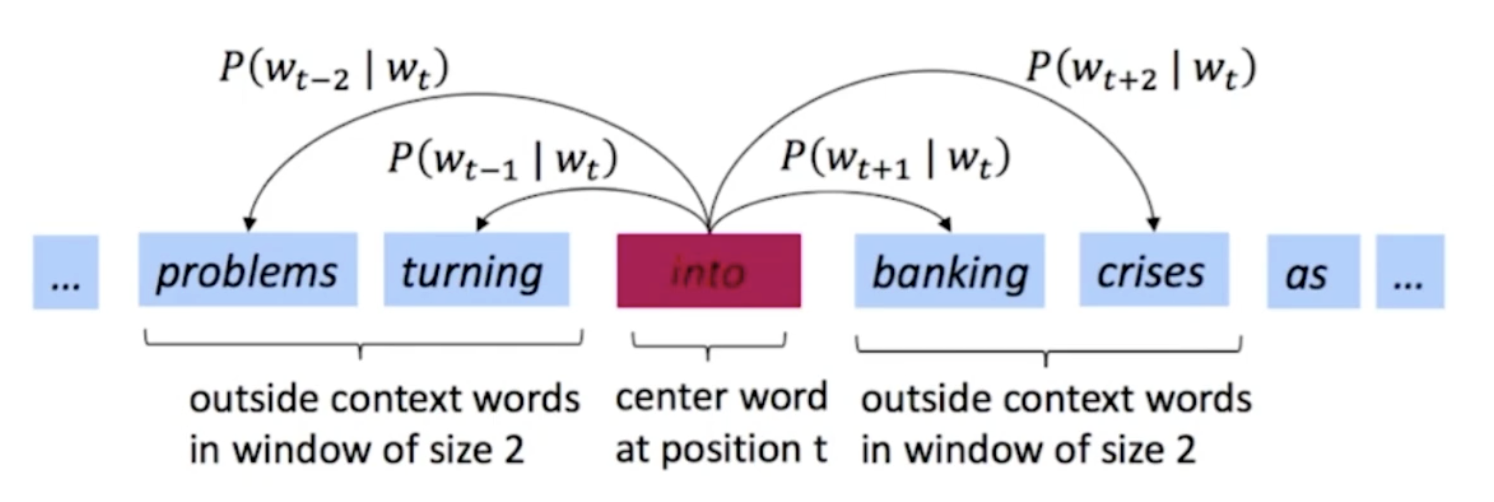

Возьмем какой-то ограниченный словарь, пусть 1000 слов, и построим таблицу, в легенду которой запишем эти слова из словаря в одинаковом порядке как во вертикали, так и по горизонтали. Получится таблица 1000 х 1000.

Для заполнения таблицы напишем программу, которая скользящим окном по 5 слов будет пробегать по большому массиву текстов и в случае, когда в пределах выбранных 5 слов будет встречаться 2 слова из словаря, то в таблице на пересечении соответствующих слов мы будем увеличивать число на 1. Соответственно, чем чаще будут встречаться слова в текстах, тем больше будут числа на их пересечении. И после обработки скажем, что вектор каждого слова - это строка/столбец (они идентичны) из этой таблицы.

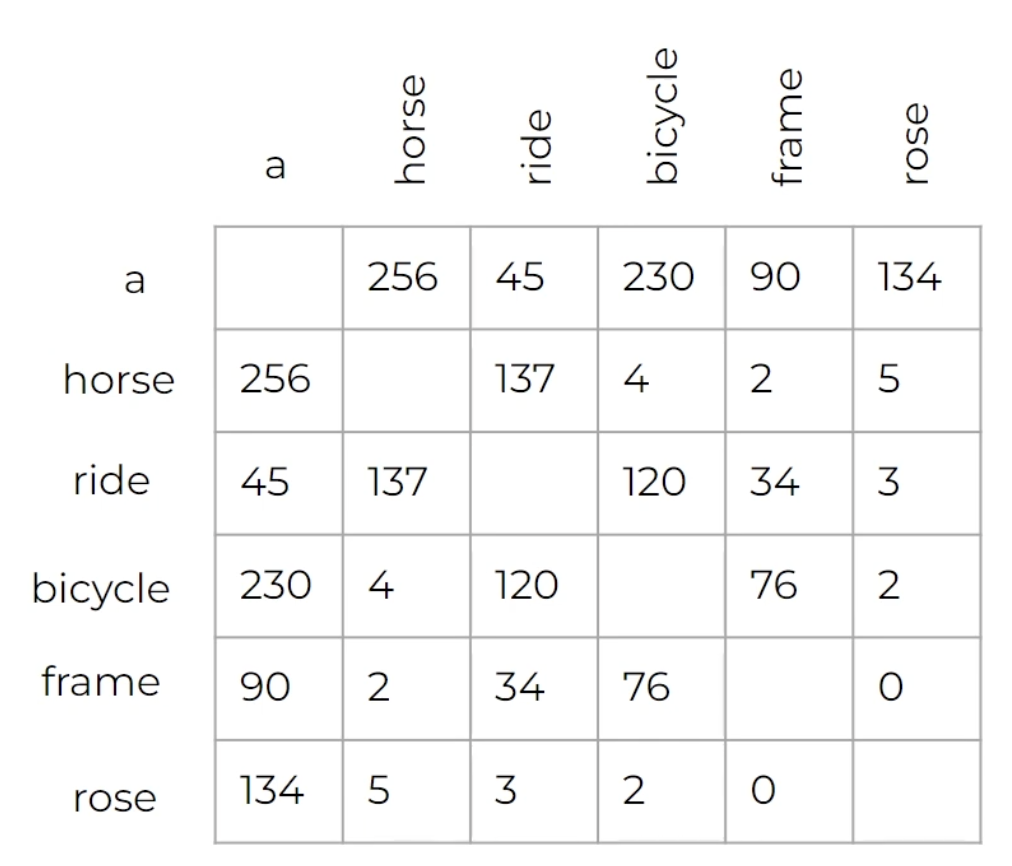

Преимущества:

- Вектор отображает смысл слова

Недостатки:

- векторы разрежены, имеют большой размер и требуют много памяти
- размер словаря ограничен, слова, не попавшие в словарь, не могут быть обработаны
- векторы редких слов не информативны

Т.е. идея неплохая, но нужно найти способ сделать эти векторы более компактными и универсальными.


# word2vec

И такая идея нашлась - научить нейросеть предсказывать значения вектора смысла. Так же, как ранее мы обучали нейросеть образу кота, сейчас мы будем обучать нейросеть предсказывать вероятность слова по его окружению (контексту).

Первым эту идею предложил Томаш Миколов, чешский аспирант, работавший в компании Google в 2013 году. И получил этот алгоритм название word2vec. Вернее, он предложил 2 разных алгоритма.

## CBOW

предсказывает текущее слово по контексту (окружающим словам).

CBOW — continuous bag of words, continuous потому, что мы скармливаем нашей модели последовательно наборы слов из текста, a BoW потому что порядок слов в контексте не важен.

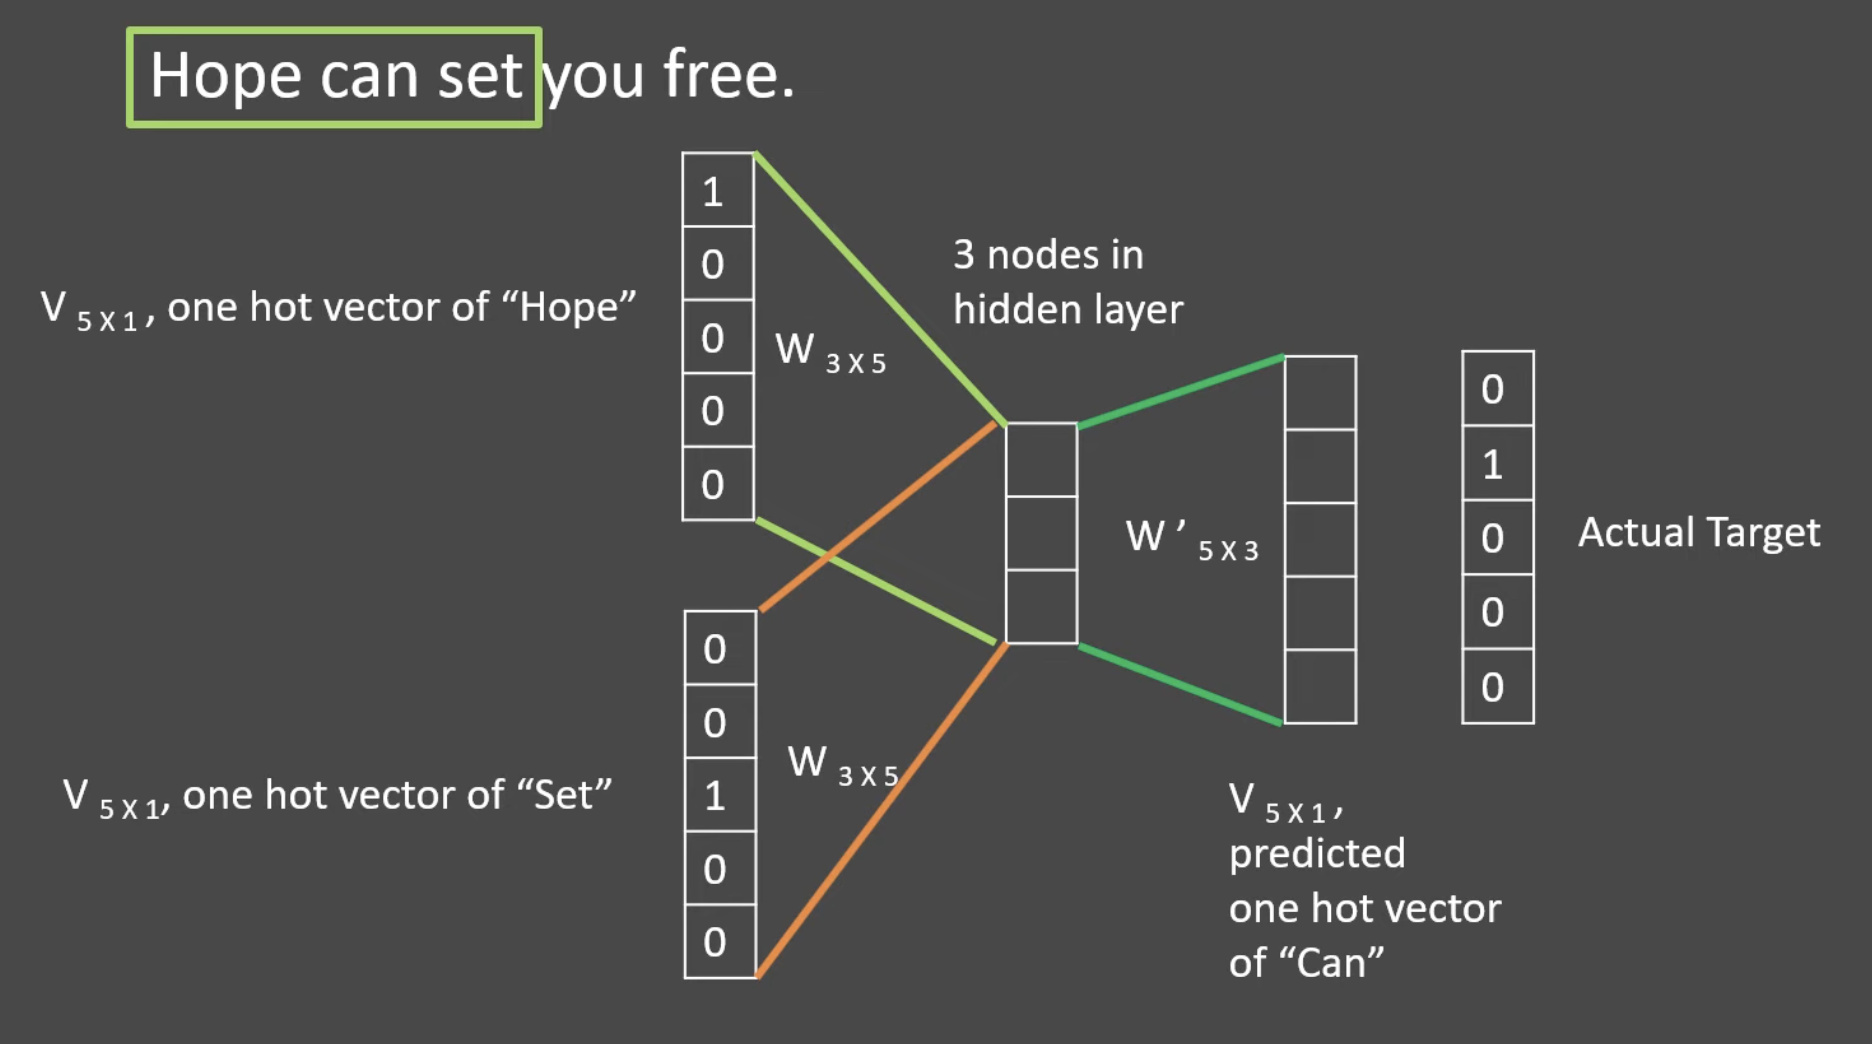

## skip-gram

“словосочетание с пропуском”. Мы пытаемся из данного нам слова угадать его контекст (точнее вектор контекста).

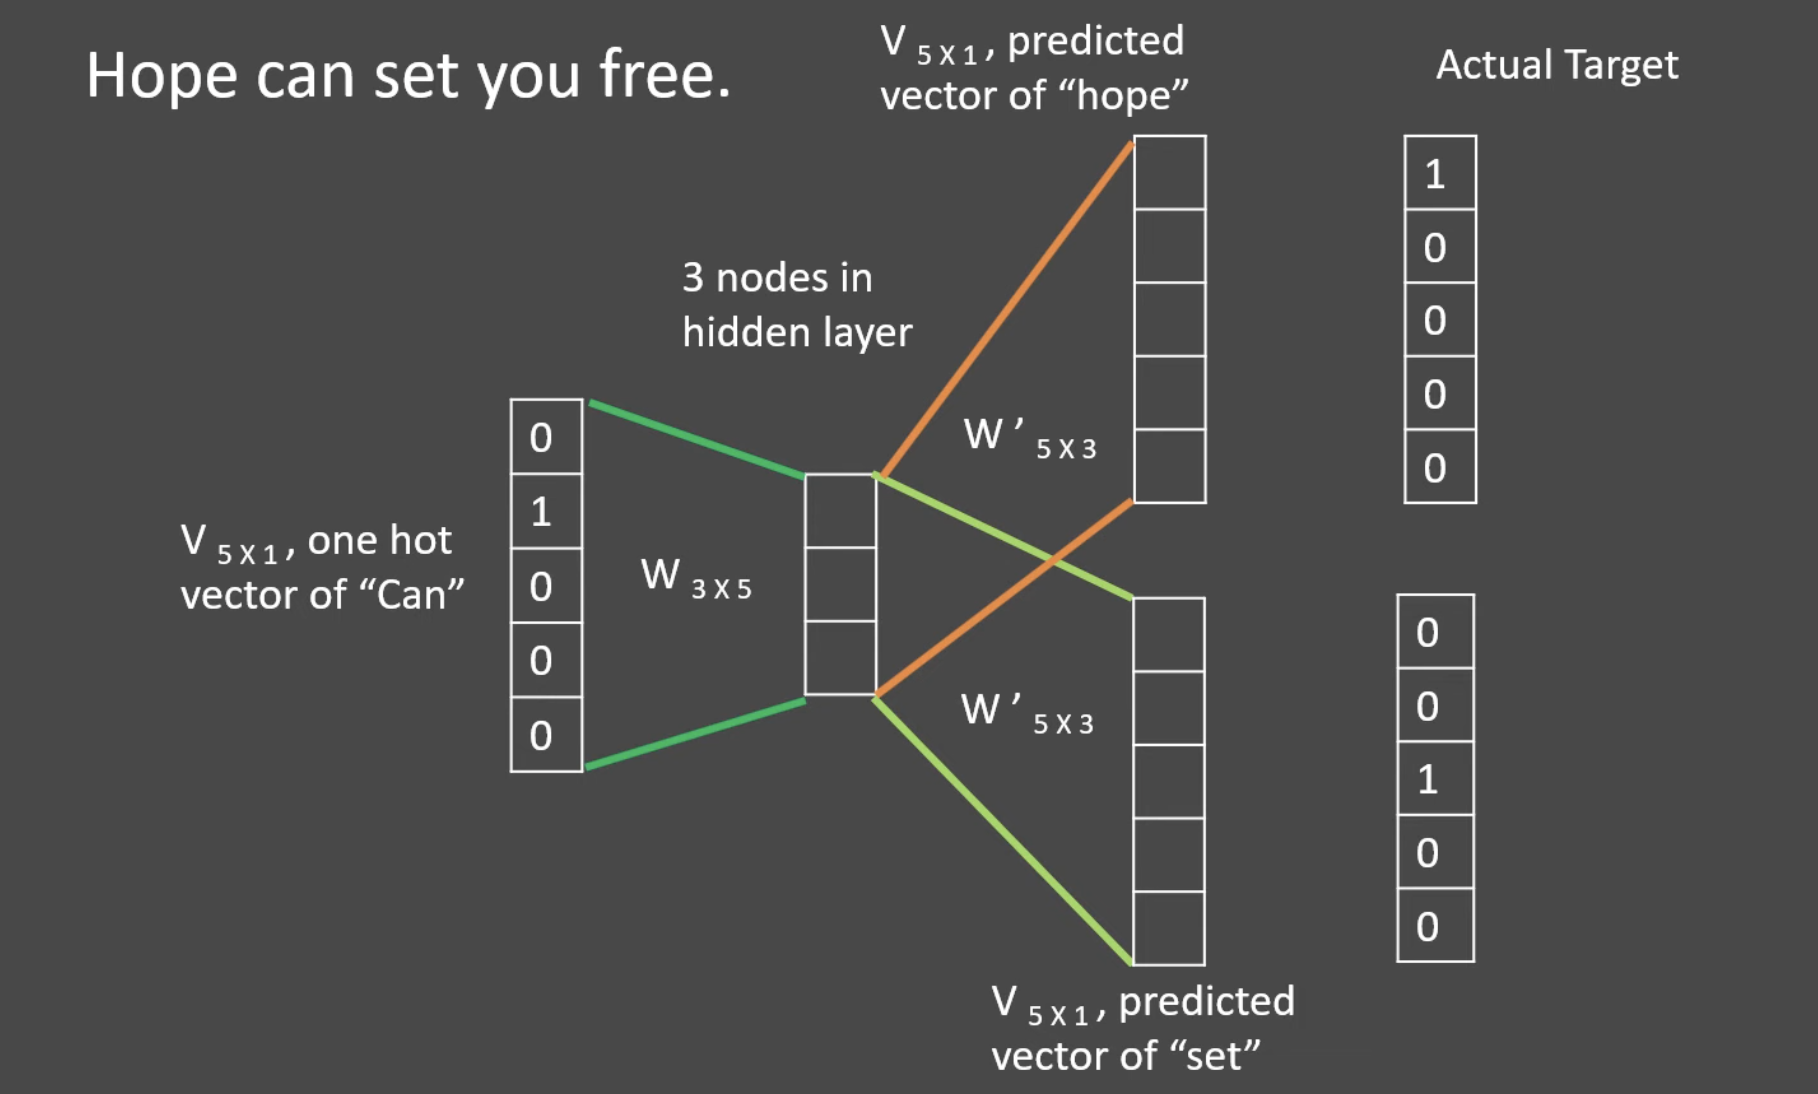

# Embedding

Как получить из обученной нейросети вектор, кодирующий смысл?

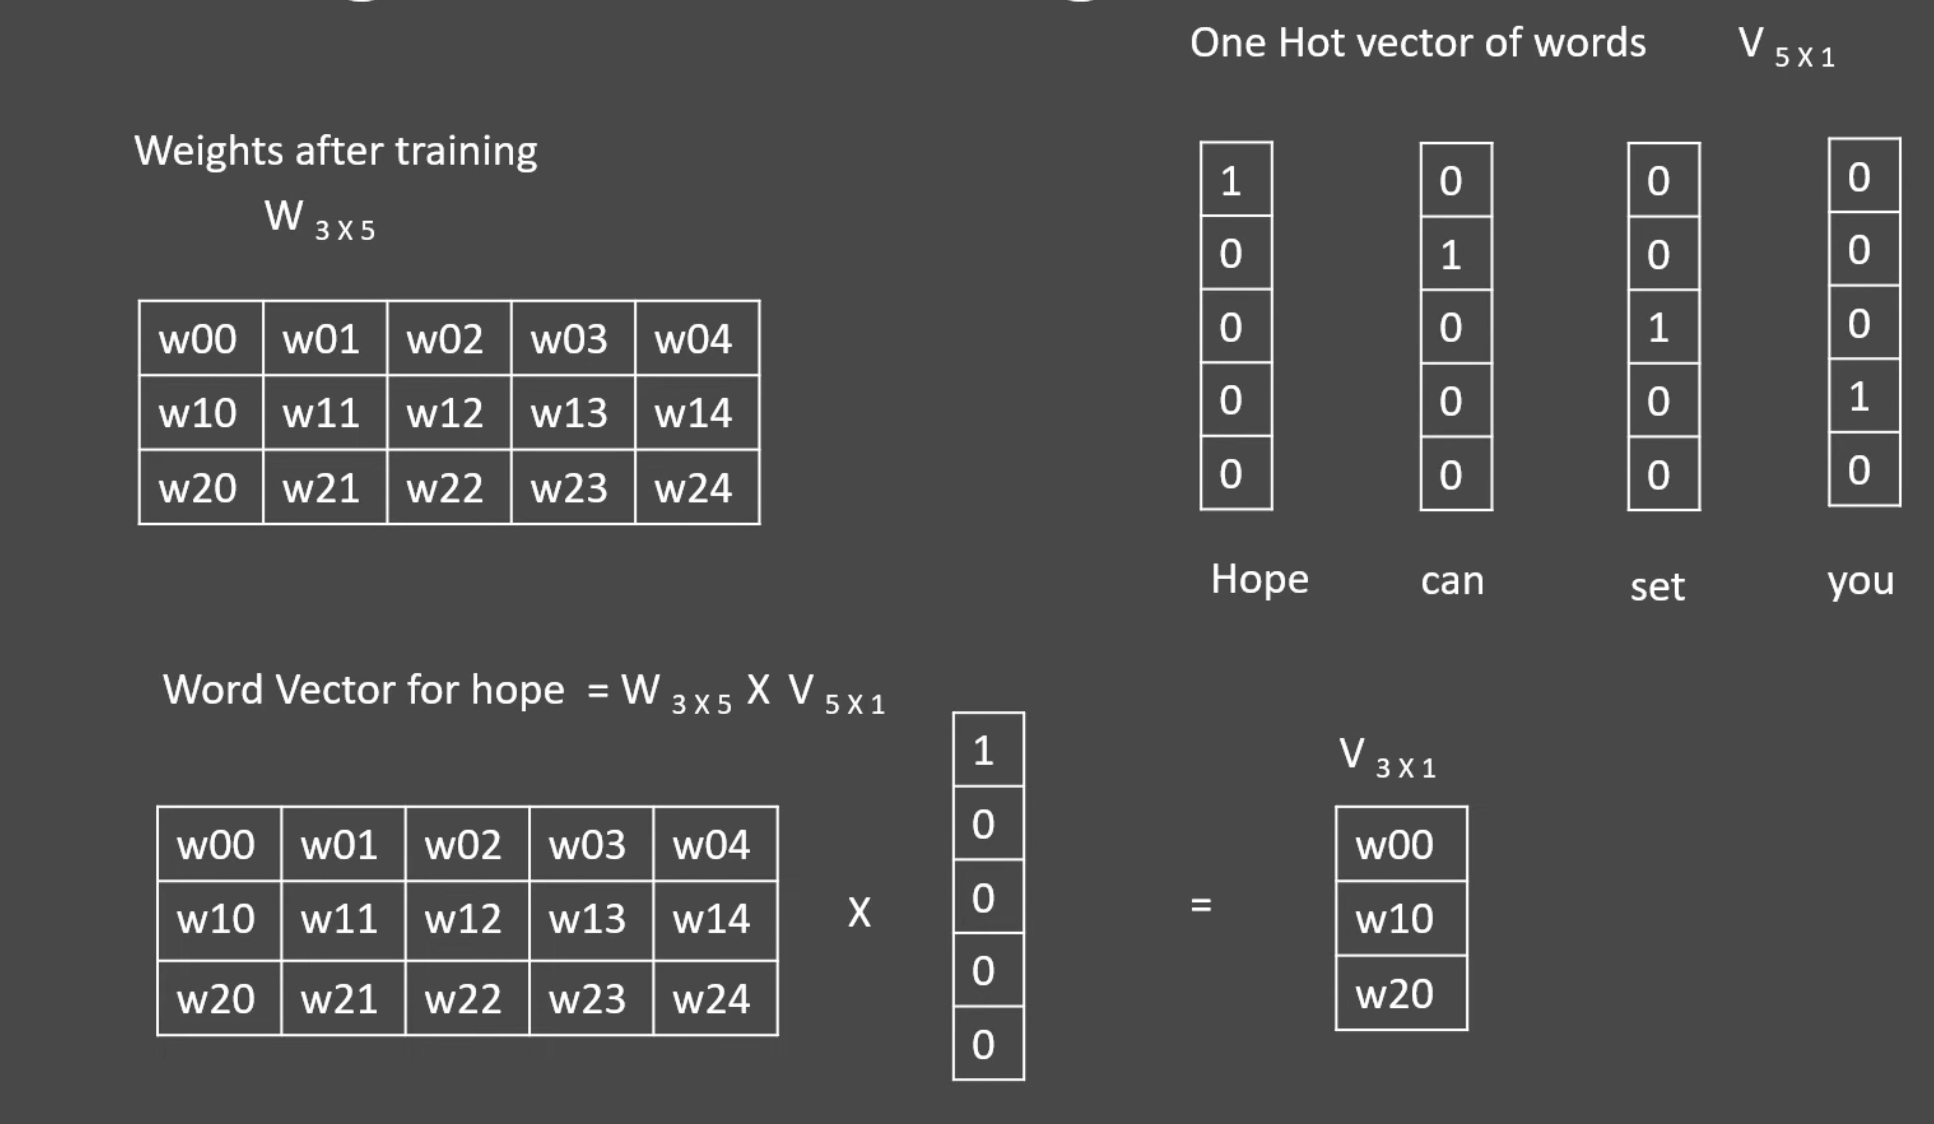

В итоге получаем вектор, расположение которого в векторном пространстве относительно других векторов демонстрирует его смысловое содержание.

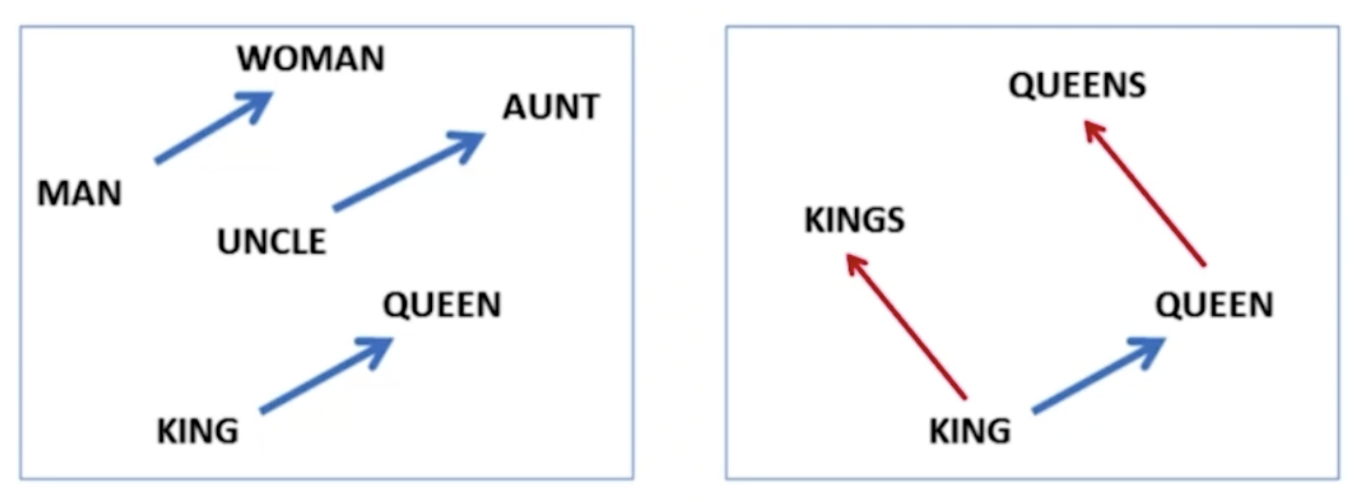

Векторная арифметика:

**v(king) - v(man) + v(woman) ≈ v(queen)**

## Пример создания эмбендингов

In [2]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 73.5 MB/s eta 0:00:00


In [3]:
import gensim # популярная NLP библиотека
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess

texts = [
    "Фрукты – кладезь витаминов и минералов, они богаты кальцием, магнием, железом, цинком и витаминами А, С, Е и К.",
    "Также фрукты – это клетчатка, которая поможет наладить работу желудочно-кишечного тракта.",
    "Однако надо быть осторожным в их употреблении: не стоит есть их слишком много.",
    "Также вредно есть фрукты и пить свежевыжатые соки натощак, так как они повышают кислотность в желудке, что может вызвать вздутие и газообразование. Некоторые фрукты очень калорийны, например, бананы и виноград, а в лимоне содержится больше сахара, чем в спелой клубнике.",
]

# Предобработка текстов
sentences = [simple_preprocess(text) for text in texts]
# Основные операции:
# Приводит к нижнему регистру - все буквы становятся строчными
# Токенизирует - разбивает текст на отдельные слова
# Удаляет пунктуацию и специальные символы
# Фильтрует токены по длине (по умолчанию от 2 до 15 символов)
# Удаляет числа (опционально)
print(sentences)

[['фрукты', 'кладезь', 'витаминов', 'минералов', 'они', 'богаты', 'кальцием', 'магнием', 'железом', 'цинком', 'витаминами'], ['также', 'фрукты', 'это', 'клетчатка', 'которая', 'поможет', 'наладить', 'работу', 'желудочно', 'кишечного', 'тракта'], ['однако', 'надо', 'быть', 'осторожным', 'их', 'употреблении', 'не', 'стоит', 'есть', 'их', 'слишком', 'много'], ['также', 'вредно', 'есть', 'фрукты', 'пить', 'свежевыжатые', 'соки', 'натощак', 'так', 'как', 'они', 'повышают', 'кислотность', 'желудке', 'что', 'может', 'вызвать', 'вздутие', 'газообразование', 'некоторые', 'фрукты', 'очень', 'калорийны', 'например', 'бананы', 'виноград', 'лимоне', 'содержится', 'больше', 'сахара', 'чем', 'спелой', 'клубнике']]


In [ ]:
model = Word2Vec(
    sentences=sentences,
    vector_size=100,  # размерность текстов
    window=5,         # размер контекстного окна
    min_count=1,      # минимальную частоту слова
    workers=4,        # количество потоков
    sg=0              # использование Continuous Bag-of-Words
)

In [ ]:
vector = model.wv['фрукты']
print("Вектор слова 'фрукты':\n", vector)

Вектор слова 'фрукты':
 [-5.2054791e-04  2.4755119e-04  5.0903256e-03  9.0211937e-03
 -9.3048699e-03 -7.1489401e-03  6.4707450e-03  9.0353293e-03
 -5.0048078e-03 -3.8135396e-03  7.4042683e-03 -1.5694889e-03
 -4.5254561e-03  6.5741660e-03 -4.8565185e-03 -1.8205482e-03
  2.9097006e-03  9.8752452e-04 -8.2780523e-03 -9.4799735e-03
  7.3154569e-03  5.0541279e-03  6.7709880e-03  7.5049448e-04
  6.3478574e-03 -3.4259120e-03 -9.9006121e-04  5.7786005e-03
 -7.4995002e-03 -3.9397008e-03 -7.5289486e-03 -9.2226535e-04
  9.5586786e-03 -7.3575699e-03 -2.3534393e-03 -1.9270481e-03
  8.0956109e-03 -5.9503722e-03  2.3051634e-05 -4.7778650e-03
 -9.6053500e-03  5.0247177e-03 -8.7435236e-03 -4.3917694e-03
 -2.9410376e-05 -3.0530943e-04 -7.6662353e-03  9.6139386e-03
  4.9918173e-03  9.2535904e-03 -8.1347190e-03  4.4616866e-03
 -4.1462504e-03  8.0564484e-04  8.5069472e-03 -4.4751824e-03
  4.5090765e-03 -6.7816582e-03 -3.5216277e-03  9.4107566e-03
 -1.6027965e-03  3.0144321e-04 -4.0966007e-03 -7.6648304e-03


In [ ]:
similar_words = model.wv.most_similar('фрукты')
print("Слова, похожие на 'фрукты':")
for word, similarity in similar_words:
    print(f"{word}: {similarity}")

Слова, похожие на 'фрукты':
очень: 0.21857285499572754
больше: 0.21744659543037415
натощак: 0.19611598551273346
железом: 0.17187251150608063
кишечного: 0.17063340544700623
свежевыжатые: 0.15181174874305725
слишком: 0.14270859956741333
минералов: 0.14079365134239197
кладезь: 0.13937461376190186
цинком: 0.12379665672779083


Преимущества:

- Векторы отражают смысл слов;
- Размерность векторов не зависит от размера словаря;
- При добавлении документов векторы можно дообучить.

Недостатки:

- Фиксированный размер словаря. При изменении размера словаря документов векторы нужно пересчитывать;
- Для редких слов эмбеддинги получаются неоптимальными;
- Слова, имеющие один корень, обрабатываются нейросетью по-разному (eat, eater, eating)

# Дальнейшее развитие текстовых эмбеддингов

## FastText

Проблема word2vec: редкие слова имеют плохие эмбеддинги, а слова, не попавшие в словарь .

Идея - будем строить векторы для частей слов, а не для целых слов.

- Делим слова на п-граммы по буквам:
apple = <ap, ppl, ple, le >
- Учим векторы для п-грамм;
- Вектор слова получаем как сумму векторов его
п-грамм.

Преимущества:

- Можно получить более адекватные эмбеддинги для редких и неизвестных слов;

Недостатки:

- n-грамм может быть очень много. Требуется больше вычислительных ресурсов.

## BERT

BERT (англ. Bidirectional Encoder Representations from Transformers) — языковая модель, основанная на архитектуре трансформер, предназначенная для предобучения языковых представлений с целью их последующего применения в широком спектре задач обработки естественного языка.

BERT обучается одновременно на двух задачах — предсказания следующего предложения (англ. next sentence prediction) и генерации пропущенного токена (англ. masked language modeling). На вход BERT подаются токенизированные пары предложений, в которых некоторые токены скрыты.


Архитектура:
- Word2Vec: Shallow (2 слоя)
- BERT: Transformer (12-24 слоя)

Размер модели
- Word2Vec: ~100 MB
- BERT: 0.4-1.3 GB

Очень кратко в чем разница результатов векторизации.Давайте рассмотрим его на примере двух предложений:

- Он взял лук и пошел на охоту
- Он добавил нарезанный лук в картошку

Несмотря на то, что в обоих предложениях мы употребляем слово "лук", его смысл абсолютно разный и отображает разные предметы. Именно тут BERT поймет разницу между двумя луками, а Word2Vec - нет, и даст один и тот же вектор для двух луков.

# Эмбеддинги в других модальностях

Эмбеддинги - это не обязательно векторное представление текста. Это может быть векторное представление любого типа информации, которую обработала нейросеть и построила карту (закодировала в весах) отношения между классифицируемыми объектами.

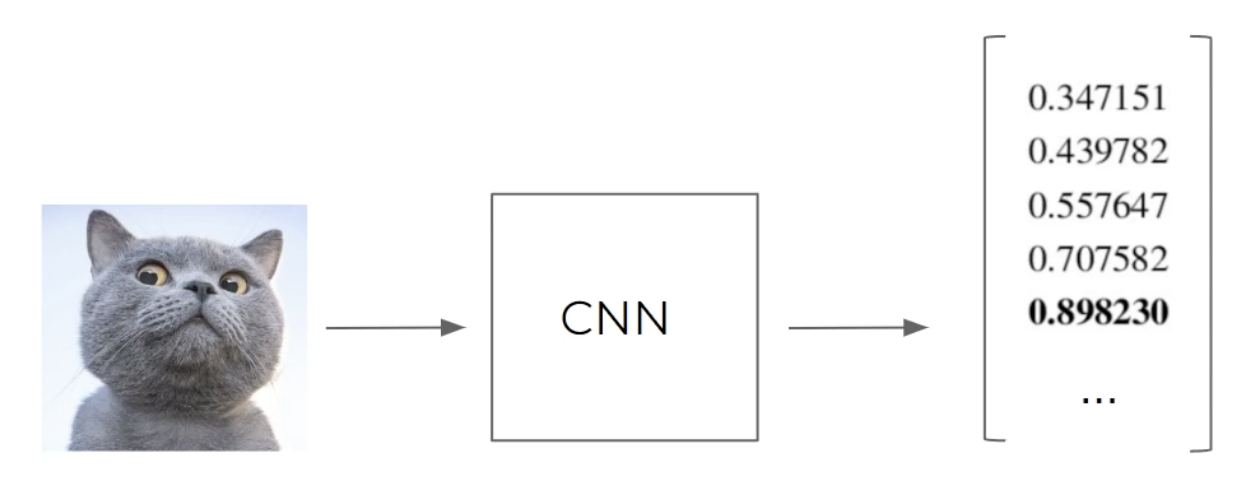

Например, при обучении светрочной нейронной сети предпоследний слой (тот, что идет перед полносвязным слоем классификации) содержит набор признаков изображения, на основании которых посносвязный слой делает классификацию. И это и есть вектора-эмбеддинги, которые описывают суть содержащихся на изображениях объектов.